In [1]:
import tensorflow as tf
import numpy as np

print(tf.__version__)
print(np.__version__)

2.12.0
1.23.5


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

In [3]:
df_normal = pd.read_csv("df_normal_processed.csv", dtype="float32", nrows=30000)
df_ddos = pd.read_csv("df_ddos_processed.csv", dtype="float32", nrows=30000)

df_normal['true_label'] = 0
df_ddos['true_label'] = 1

df = pd.concat([df_normal, df_ddos], axis=0)

X = df.drop(columns=['true_label'])
y = df['true_label']

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [5]:
X_train_normal = X_train_scaled[y_train == 0]

In [6]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

input_dim = X_train_normal.shape[1]

input_layer = Input(shape=(input_dim,))
encoded = Dense(64, activation="relu")(input_layer)
encoded = Dense(32, activation="relu")(encoded)

decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(input_dim, activation="linear")(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)
autoencoder.compile(optimizer="adam", loss="mse")

autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=20,
    batch_size=256,
    validation_split=0.1
)

Epoch 1/20
21/21 [==============================] - 3s 24ms/step - loss: 0.3740 - val_loss: 0.3845
Epoch 2/20
21/21 [==============================] - 0s 7ms/step - loss: 0.3606 - val_loss: 0.3709
Epoch 3/20
21/21 [==============================] - 0s 8ms/step - loss: 0.3424 - val_loss: 0.3550
Epoch 4/20
21/21 [==============================] - 0s 9ms/step - loss: 0.3224 - val_loss: 0.3412
Epoch 5/20
21/21 [==============================] - 0s 7ms/step - loss: 0.3017 - val_loss: 0.3313
Epoch 6/20
21/21 [==============================] - 0s 7ms/step - loss: 0.2825 - val_loss: 0.3244
Epoch 7/20
21/21 [==============================] - 0s 8ms/step - loss: 0.2625 - val_loss: 0.3194
Epoch 8/20
21/21 [==============================] - 0s 7ms/step - loss: 0.2441 - val_loss: 0.3149
Epoch 9/20
21/21 [==============================] - 0s 6ms/step - loss: 0.2324 - val_loss: 0.3115
Epoch 10/20
21/21 [==============================] - 0s 6ms/step - loss: 0.2162 - val_loss: 0.3075
Epoch 11/20
21/21 

In [7]:
print(df_normal.shape)
print(df_ddos.shape)

(7179, 776)
(30000, 776)


In [8]:
import numpy as np

X_test_pred = autoencoder.predict(X_test_scaled)

mse = np.mean(np.power(X_test_scaled - X_test_pred, 2), axis=1)

df_eval = pd.DataFrame({
    "reconstruction_error": mse,
    "true_label": y_test.values
})

233/233 [==============================] - 1s 2ms/step


In [9]:
normal_errors = df_eval[df_eval['true_label'] == 0]['reconstruction_error']

threshold = np.percentile(normal_errors, 95)

df_eval['predicted_label'] = (
    df_eval['reconstruction_error'] > threshold
).astype(int)

In [10]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(df_eval['true_label'], df_eval['predicted_label'])

print(cm)
print(classification_report(df_eval['true_label'], df_eval['predicted_label']))

[[1364   72]
 [3676 2324]]
              precision    recall  f1-score   support

           0       0.27      0.95      0.42      1436
           1       0.97      0.39      0.55      6000

    accuracy                           0.50      7436
   macro avg       0.62      0.67      0.49      7436
weighted avg       0.83      0.50      0.53      7436



In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score

for t in [80, 85, 90, 95]:
    thr = np.percentile(normal_errors, t)
    preds = (df_eval['reconstruction_error'] > thr).astype(int)
    
    print(f"\nThreshold {t}%")
    print("Precision:", precision_score(y_test, preds))
    print("Recall:", recall_score(y_test, preds))
    print("F1:", f1_score(y_test, preds))


Threshold 80%
Precision: 0.9542556582722346
Recall: 0.9978333333333333
F1: 0.9755580902721199

Threshold 85%
Precision: 0.9641850439396452
Recall: 0.9691666666666666
F1: 0.9666694372870086

Threshold 90%
Precision: 0.948294434470377
Recall: 0.44016666666666665
F1: 0.6012521343198634

Threshold 95%
Precision: 0.9699499165275459
Recall: 0.3873333333333333
F1: 0.5535969509290138


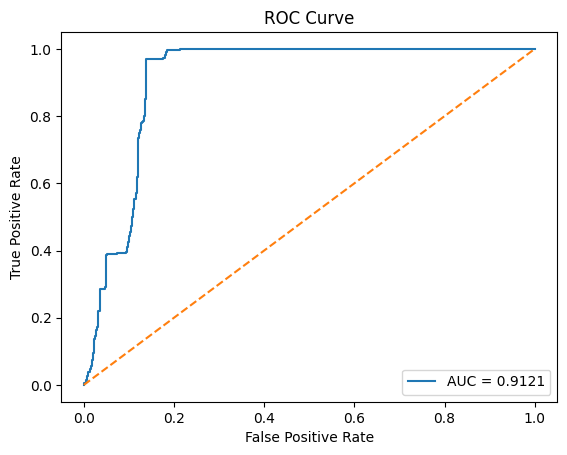

In [12]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(
    df_eval['true_label'],
    df_eval['reconstruction_error']
)

roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],'--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.show()

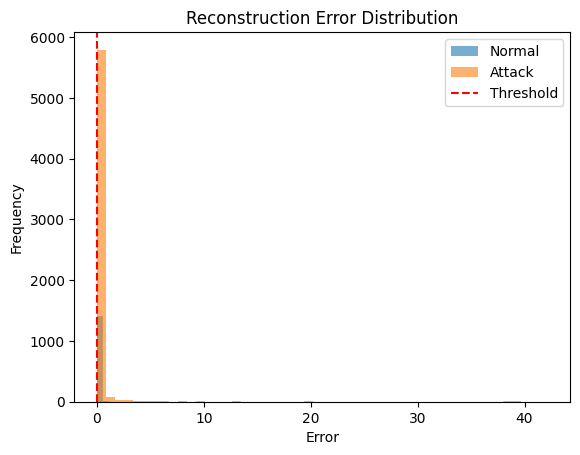

In [13]:
plt.figure()

plt.hist(df_eval[df_eval['true_label'] == 0]['reconstruction_error'],
         bins=50, alpha=0.6, label='Normal')

plt.hist(df_eval[df_eval['true_label'] == 1]['reconstruction_error'],
         bins=50, alpha=0.6, label='Attack')

plt.axvline(threshold, color='red', linestyle='--', label='Threshold')

plt.legend()
plt.title("Reconstruction Error Distribution")
plt.xlabel("Error")
plt.ylabel("Frequency")

plt.show()

In [14]:
df_eval.to_csv("df_eval_with_ae.csv", index=False)

print("✅ Autoencoder results saved")

✅ Autoencoder results saved


In [15]:
from sklearn.metrics import classification_report, confusion_matrix

In [16]:
from sklearn.metrics import confusion_matrix

for p in [95, 90, 85, 80]:
    
    normal_errors = df_eval[df_eval["true_label"] == 0]["reconstruction_error"]
    
    threshold = np.percentile(normal_errors, p)
    
    df_eval[f'ae_anomaly_{p}'] = (
        df_eval['reconstruction_error'] > threshold
    ).astype(int)
    
    print(f"\nThreshold = {p}%")
    print(confusion_matrix(df_eval['true_label'], df_eval[f'ae_anomaly_{p}']))
    


Threshold = 95%
[[1364   72]
 [3676 2324]]

Threshold = 90%
[[1292  144]
 [3359 2641]]

Threshold = 85%
[[1220  216]
 [ 185 5815]]

Threshold = 80%
[[1149  287]
 [  13 5987]]


In [17]:
print(df_eval.columns)

Index(['reconstruction_error', 'true_label', 'predicted_label',
       'ae_anomaly_95', 'ae_anomaly_90', 'ae_anomaly_85', 'ae_anomaly_80'],
      dtype='object')


In [18]:
print(df_eval['true_label'].value_counts())

true_label
1    6000
0    1436
Name: count, dtype: int64


In [19]:
thr = np.percentile(normal_errors, p)

In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

for t in ['95','90','85','80']:
    y_true = df_eval['true_label']
    y_pred = df_eval[f'ae_anomaly_{t}']
    
    print(f"\nThreshold {t}%")
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1:", f1_score(y_true, y_pred))


Threshold 95%
Precision: 0.9699499165275459
Recall: 0.3873333333333333
F1: 0.5535969509290138

Threshold 90%
Precision: 0.948294434470377
Recall: 0.44016666666666665
F1: 0.6012521343198634

Threshold 85%
Precision: 0.9641850439396452
Recall: 0.9691666666666666
F1: 0.9666694372870086

Threshold 80%
Precision: 0.9542556582722346
Recall: 0.9978333333333333
F1: 0.9755580902721199


In [21]:
import sys
!"{sys.executable}" -m pip install seaborn


[notice] A new release of pip is available: 23.0.1 -> 26.1.1
[notice] To update, run: C:\Users\Arushi Sharma\thesis_env\Scripts\python.exe -m pip install --upgrade pip


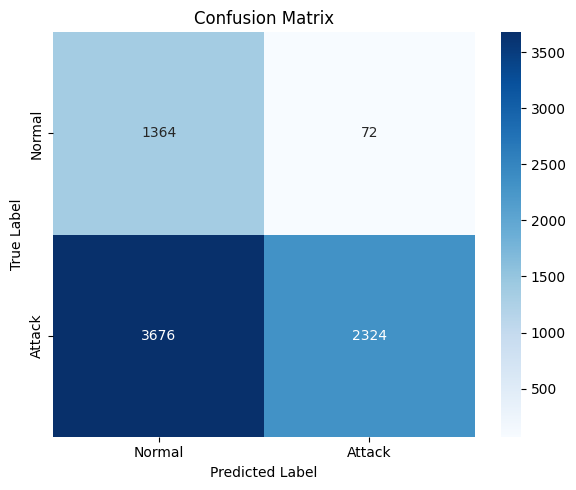

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    df_eval['true_label'],
    df_eval['predicted_label']
)

labels = ["Normal", "Attack"]

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

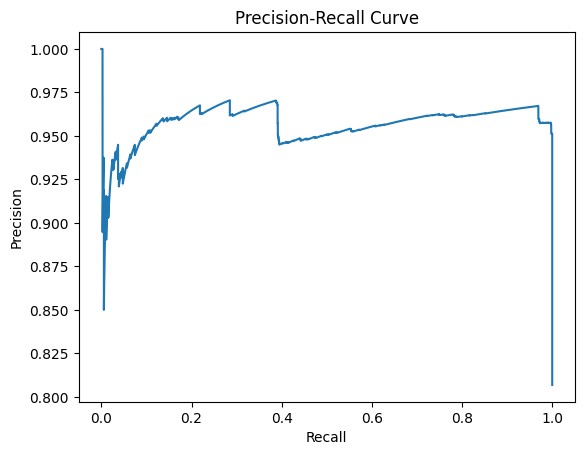

In [23]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(
    df_eval['true_label'],
    df_eval['reconstruction_error']
)

plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.savefig("precision_recall_curve.png")
plt.show()